# Sri Lankan fuel data preprocessing — all nine grades

## tl;dr
This workflow regenerates the cleaned CPC records, the final nine-fuel table and nine individual fuel CSVs. The final table has 1,665 rows: 1,576 observed prices and 89 blank prices with explicit quality status. All 513 observations in the supplied CSV, including both petrol grades, match existing CPC prices and add provenance without duplicate training observations.

## Context & Methods
The intermediate grain is a CPC revision record. The final grain is one revision record and one fuel type, keyed by (source_record_id, fuel_code). Date alone is not unique. All nine fuel grades are retained; the earlier three-fuel forecasting-input file remains an optional subset.

### Key Assumptions
- Preserve all original source records, same-day entries and valid prices.
- The intermediate stage reconciles diesel and kerosene; final consolidation additionally reconciles supplied petrol.
- The supplied compilation shares CPC provenance; matching prices are not independent verification.
- Blank prices remain blank. Distinguish unreported values from invalid source values.
- Measurement units are litre only on exact matches evidenced by the supplied CSV; other units remain unverified.
- No filling, monthly resampling, feature engineering or training is performed.

## Data
### 1. Load source snapshots and regenerate intermediate cleaning outputs

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display
BASE = Path.cwd()
if not (BASE / 'fuel_preprocessing.py').exists():
    BASE = BASE / 'ceypetco_data_cleaning'
sys.path.insert(0, str(BASE))
from fuel_preprocessing import run
clean, supplied, reconciliation, target, summary = run(BASE)
display(pd.DataFrame([summary]).drop(columns=['input_sha256', 'reconciliation']))
print('Input SHA-256 hashes:', json.dumps(summary['input_sha256'], indent=2))

,cpc_fuel_records,cleaned_fuel_records,first_date,last_date,supplied_rows,supplied_diesel_kerosene_rows,invalid_numeric_cells,checks_passed,checks_total
0,185,185,1990-03-01,2026-11-02,513,299,1,10,10


Input SHA-256 hashes: {
  "ceypetco_historical_prices_all.csv": "8eacf1e5af41781ca0137aba7f7e401ac460f33b3704277ff9d3b7dbb453482e",
  "fuel-prices-2026-10-15.csv": "24bb671378b48b70e6f4cbd919d06845b92f0bed1611ae7f77142948d6fb6b00"
}


### 2. Review intermediate diesel/kerosene reconciliation
This intermediate audit covers 299 supplied observations. The final stage below additionally checks the supplied petrol observations.

In [2]:
display(pd.crosstab(reconciliation.indicator, reconciliation.status))
display(reconciliation.head(6))

status,matched_existing
indicator,
Auto diesel,111
Kerosene,79
Super diesel,109


,date,indicator,value,unit,status,matching_source_record_ids,source_file,source
0,1990-03-01,Auto diesel,9.60,Rs per litre,matched_existing,fcab05ca-30a7-4876-b61a-097287226132,fuel-prices-2026-10-15.csv,cpc-historical-prices-api
1,1990-03-01,Super diesel,10.90,Rs per litre,matched_existing,fcab05ca-30a7-4876-b61a-097287226132,fuel-prices-2026-10-15.csv,cpc-historical-prices-api
2,1990-03-01,Kerosene,6.58,Rs per litre,matched_existing,fcab05ca-30a7-4876-b61a-097287226132,fuel-prices-2026-10-15.csv,cpc-historical-prices-api
3,1990-08-14,Auto diesel,11.00,Rs per litre,matched_existing,e263c9a5-44c8-468f-b2ee-34a04783662d,fuel-prices-2026-10-15.csv,cpc-historical-prices-api
4,1990-08-14,Super diesel,12.50,Rs per litre,matched_existing,e263c9a5-44c8-468f-b2ee-34a04783662d,fuel-prices-2026-10-15.csv,cpc-historical-prices-api
5,1990-08-14,Kerosene,8.00,Rs per litre,matched_existing,e263c9a5-44c8-468f-b2ee-34a04783662d,fuel-prices-2026-10-15.csv,cpc-historical-prices-api


### 3. Inspect quality checks and unresolved records
Invalid numeric values remain available in the raw source and are withheld from numeric exports. Repeated dates are retained for review.

In [3]:
display(pd.read_csv(BASE / 'reports/validation_checks.csv'))
display(pd.read_csv(BASE / 'reports/cleaning_issues.csv'))

,check,passed
0,fuel_only,True
1,unique_source_record_ids,True
2,valid_dates,True
3,positive_numeric_prices,True
4,supplied_values_positive,True
5,supplied_keys_unique,True
6,all_supplied_rows_audited,True
7,no_unreviewed_conflicts,True
8,target_products_only,True
9,original_cpc_records_preserved,True


,source_record_id,date,field,raw_value,issue,action
0,c9608dee-f849-4852-8e5c-e7392682bd51,2008-12-06,fur_800,53.9.00,invalid_numeric,numeric value withheld; original retained in r...


### 4. Build the final nine-fuel dataset and individual CSVs
The build stage reshapes the cleaned table and reconciles all five supplied series, including Petrol 92 and Petrol 95. The split stage reads each saved file back and verifies that recombining all nine files exactly reproduces the final dataset. File hashes and counts are recorded in the reports folder.

In [4]:
from build_final_dataset import build
from split_fuel_datasets import split
final_summary = build()
manifest = split()
final = pd.read_csv(BASE / 'data/cleaned/fuel_prices_final_cleaned.csv')
display(pd.DataFrame([{k: v for k, v in final_summary.items()
                       if k not in ['input_sha256', 'price_status_counts']}]))
print('Final price status:', final_summary['price_status_counts'])

petrol_92_cleaned.csv: 185 records; 185 valid prices
petrol_95_cleaned.csv: 185 records; 185 valid prices
auto_diesel_cleaned.csv: 185 records; 185 valid prices
super_diesel_cleaned.csv: 185 records; 185 valid prices
kerosene_cleaned.csv: 185 records; 185 valid prices
industrial_kerosene_cleaned.csv: 185 records; 185 valid prices
furnace_oil_800_cleaned.csv: 185 records; 184 valid prices
furnace_oil_1500_high_cleaned.csv: 185 records; 97 valid prices
furnace_oil_1500_low_cleaned.csv: 185 records; 185 valid prices
Verified 1665 records across 9 files.


,rows,fuel_types,observed_prices,missing_prices,supplied_observations_matched
0,1665,9,1576,89,513


Final price status: {'observed': 1576, 'not_reported': 88, 'invalid_source_value': 1}


## Results
### 5. Inspect all nine output files and missing-price counts
Each fuel retains 185 source revision slots. Missing prices are retained as audit records, not invented or treated as zeros. Furnace Oil 1500 High has 88 unreported prices; Furnace Oil 800 has one invalid numeric source value.

In [5]:
display(manifest.drop(columns='sha256'))
display(pd.read_csv(BASE / 'reports/final_dataset_checks.csv'))
display(pd.crosstab(final.fuel_type, final.price_status))
display(pd.read_csv(BASE / 'reports/final_source_reconciliation.csv').groupby('fuel_code').agg(
    supplied_observations=('status', 'size'), matched_observations=('status', lambda s: s.eq('matched').sum())))
print('Split validation:', (BASE / 'reports/per_fuel_dataset_validation.json').read_text())

,fuel_type,filename,records,observed_prices,missing_prices,first_date,last_date
0,Petrol 92,petrol_92_cleaned.csv,185,185,0,1990-03-01,2026-11-02
1,Petrol 95,petrol_95_cleaned.csv,185,185,0,1990-03-01,2026-11-02
2,Auto Diesel,auto_diesel_cleaned.csv,185,185,0,1990-03-01,2026-11-02
3,Super Diesel,super_diesel_cleaned.csv,185,185,0,1990-03-01,2026-11-02
4,Kerosene,kerosene_cleaned.csv,185,185,0,1990-03-01,2026-11-02
5,Industrial Kerosene,industrial_kerosene_cleaned.csv,185,185,0,1990-03-01,2026-11-02
6,Furnace Oil 800,furnace_oil_800_cleaned.csv,185,184,1,1990-03-01,2026-11-02
7,Furnace Oil 1500 High,furnace_oil_1500_high_cleaned.csv,185,97,88,1990-03-01,2026-11-02
8,Furnace Oil 1500 Low,furnace_oil_1500_low_cleaned.csv,185,185,0,1990-03-01,2026-11-02


,check,passed
0,nine_fuel_types,True
1,one_row_per_source_record_and_fuel,True
2,all_source_record_fuel_pairs_preserved,True
3,all_supplied_observations_matched,True
4,all_observed_prices_positive,True
5,all_dates_valid,True
6,missing_prices_have_explicit_status,True
7,source_price_round_trip_preserved,True


price_status,invalid_source_value,not_reported,observed
fuel_type,,,
Auto Diesel,0,0,185
Furnace Oil 1500 High,0,88,97
Furnace Oil 1500 Low,0,0,185
Furnace Oil 800,1,0,184
Industrial Kerosene,0,0,185
Kerosene,0,0,185
Petrol 92,0,0,185
Petrol 95,0,0,185
Super Diesel,0,0,185


,supplied_observations,matched_observations
fuel_code,,
lad,111,111
lk,79,79
lp_92,111,111
lp_95,103,103
lsd,109,109


Split validation: {
  "files": 9,
  "records": 1665,
  "source_file": "fuel_prices_final_cleaned.csv",
  "source_sha256": "02858a9545d8617d1293a44265b3ca9fd5fdb768a9e703ce313f2fc2d9a14eed",
  "round_trip_values_preserved": true,
  "combined_exactly_matches_final_dataset": true,
  "unique_source_record_fuel_keys": true
}


### 6. Inspect observed prices for all nine fuel types
Points show valid published prices; blank prices are not plotted. No connecting lines are drawn because gaps do not establish uninterrupted coverage. The y-axis shows the published LKR value; do not assume an unverified product measurement unit.

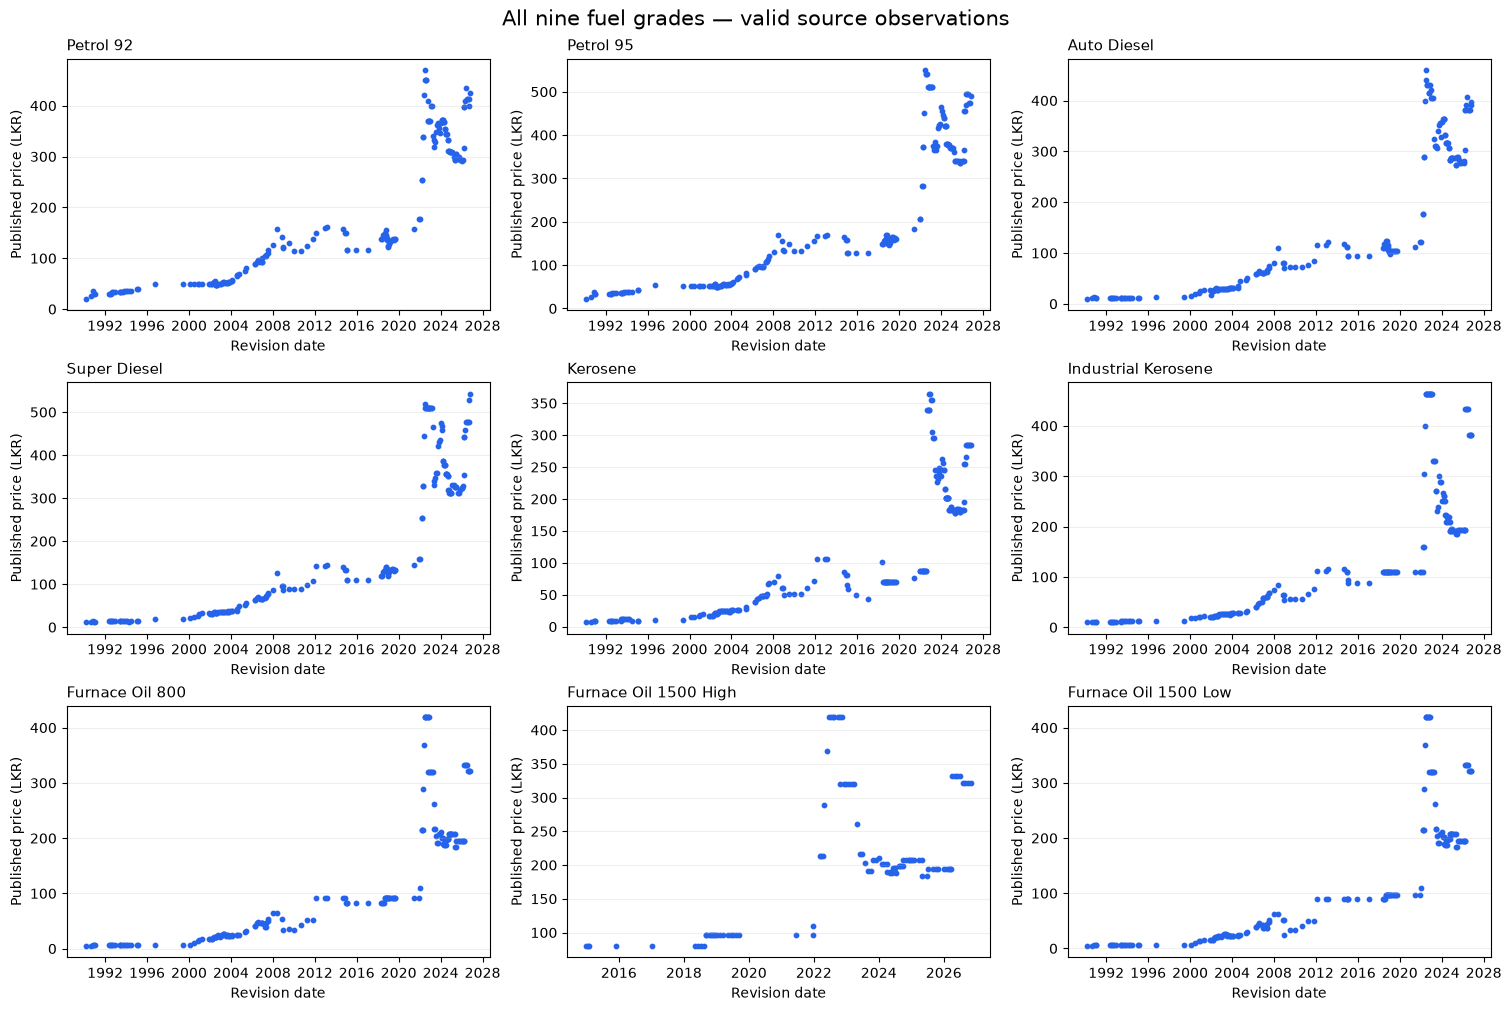

In [6]:
import matplotlib.pyplot as plt
from build_final_dataset import PRODUCTS
fig, axes = plt.subplots(3, 3, figsize=(15, 10), constrained_layout=True)
for ax, fuel in zip(axes.flat, PRODUCTS.values()):
    series = final.loc[final.fuel_type.eq(fuel) & final.price_lkr.notna()]
    ax.scatter(pd.to_datetime(series.date), series.price_lkr, s=10, color='#2563eb')
    ax.set_title(fuel, loc='left', fontsize=11)
    ax.set_ylabel('Published price (LKR)')
    ax.set_xlabel('Revision date')
    ax.grid(axis='y', alpha=.2)
fig.suptitle('All nine fuel grades — valid source observations', fontsize=15)
fig.savefig(BASE / 'reports/fuel_observations.png', dpi=140)
plt.show()

## Takeaways
The final combined dataset and nine separate fuel CSVs preserve 1,665 source-record/fuel pairs and all 1,576 valid prices. The 89 blank prices remain explicitly flagged: 88 not reported and one invalid source value. All 513 supplied observations match existing CPC prices; none are added as duplicate training rows.

Use `data/cleaned/fuel_prices_final_cleaned.csv` for all fuels or the files in `data/cleaned/by_fuel_type/` for individual fuels. The README inside that folder lists the files and usable-price counts. The three-fuel `fuel_forecasting_inputs_long.csv` is an earlier subset, not the consolidated nine-fuel output.

Reports include `data_quality_report.md`, `final_dataset_summary.csv`, `final_dataset_checks.csv`, `final_source_reconciliation.csv`, `per_fuel_dataset_manifest.csv` and `per_fuel_dataset_validation.json`. The split checks preserve every column and blank value and verify the combined result exactly against the final table.

Before forecasting, resolve same-day ordering, verify units and historical grade continuity, establish coverage, and choose a documented monthly aggregation policy. Missing-price rows cannot be numeric model targets. These are cleaned revision records, not a finished monthly training dataset.